Instructions to run:
- This notebook is configured to run in google colab, with the T4 GPU.
- Create a huggingface account and request access to this model https://huggingface.co/meta-llama/Llama-3.2-3B to run, approval may take a few minutes.  

In [1]:
from IPython.display import clear_output

In [2]:
!uv pip install "tribev2[plotting] @ git+https://github.com/facebookresearch/tribev2.git"
clear_output()

In [3]:
!pip install --force-reinstall --no-deps torchaudio==2.6.0 --index-url https://download.pytorch.org/whl/cu124 
clear_output()

In [4]:
import os

try:
    from google.colab import userdata
    os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
except:
    print("Restart kernel after this step!")
    pass


from huggingface_hub import login
login()

clear_output()

In [5]:
from tribev2.demo_utils import TribeModel, download_file
from tribev2.plotting import PlotBrain
from pathlib import Path

CACHE_FOLDER = Path("./cache")
model = TribeModel.from_pretrained("facebook/tribev2", cache_folder=CACHE_FOLDER)
plotter = PlotBrain(mesh="fsaverage5")

clear_output()

In [7]:
videos = ["https://download.blender.org/demo/movies/lumberjacks.avi", 
          "https://download.blender.org/durian/trailer/sintel_trailer-480p.mp4"]
results = {}
segments = {}

for url in videos:
    video_name = str(url.split("/")[-1])
    
    video_path = CACHE_FOLDER / video_name
    download_file(url, video_path)
    
    df = model.get_events_dataframe(video_path=video_path)
    preds, segment = model.predict(events=df)
    
    results[video_name] = preds
    segments[video_name] = segment
    
    print(f"Finished predicting fmri responses for {video_name}")
    clear_output()

Plotting...: 100%|██████████| 15/15 [00:03<00:00,  4.84it/s]


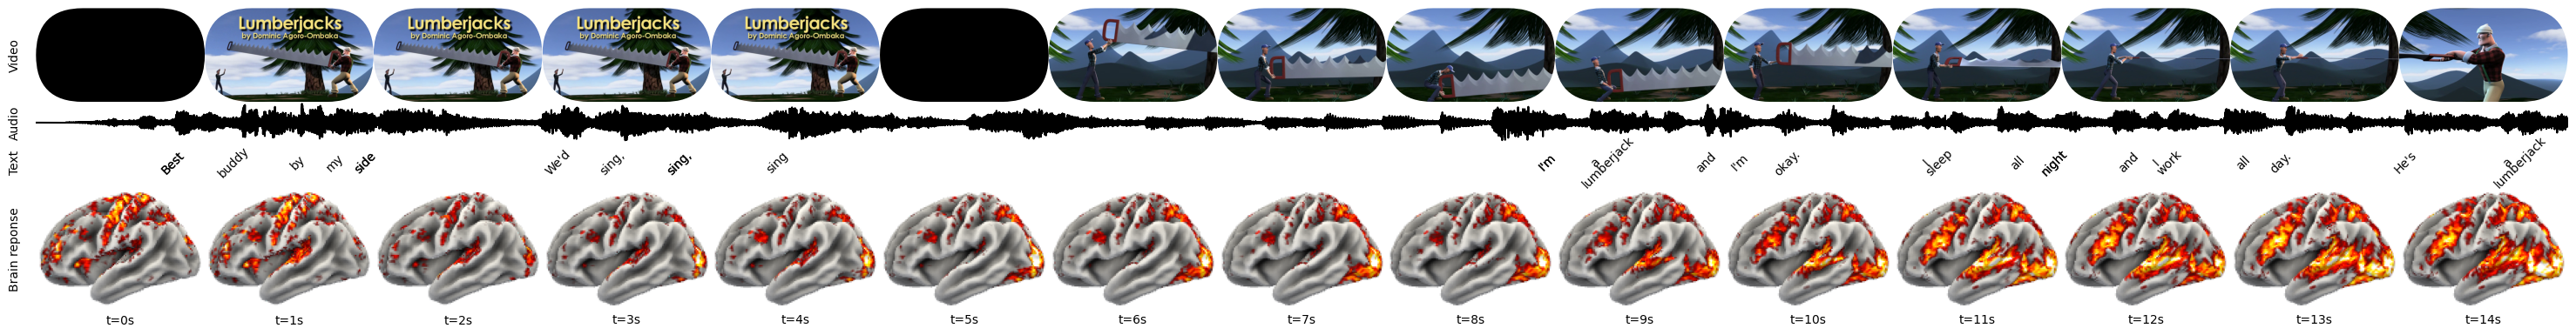

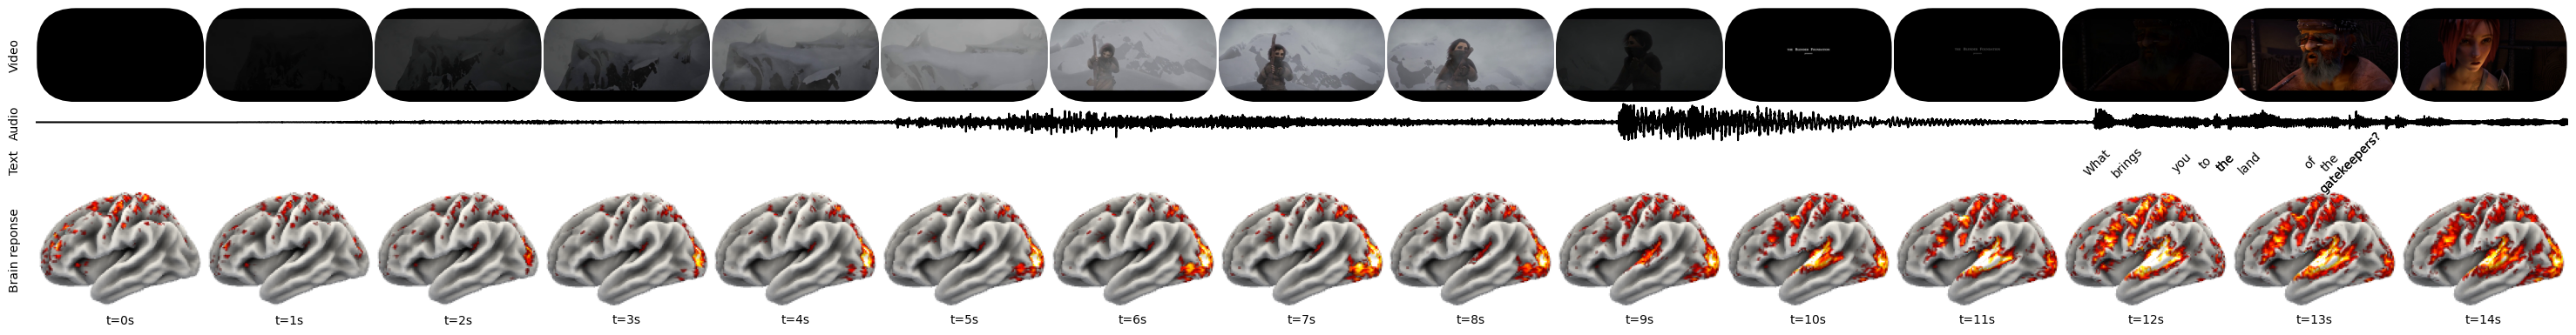

In [8]:
for video_name, pred in results.items():
    num_timesteps = min(15, preds.shape[0])
    fig = plotter.plot_timesteps(
        pred[:num_timesteps], 
        segments=segments[video_name][:num_timesteps], 
        cmap="fire", 
        norm_percentile=99, 
        vmin=0.6, 
        alpha_cmap=(0, 0.2), 
        show_stimuli=True,
    )

Text(0.5, 1.0, 'Predicted Neural Activity')

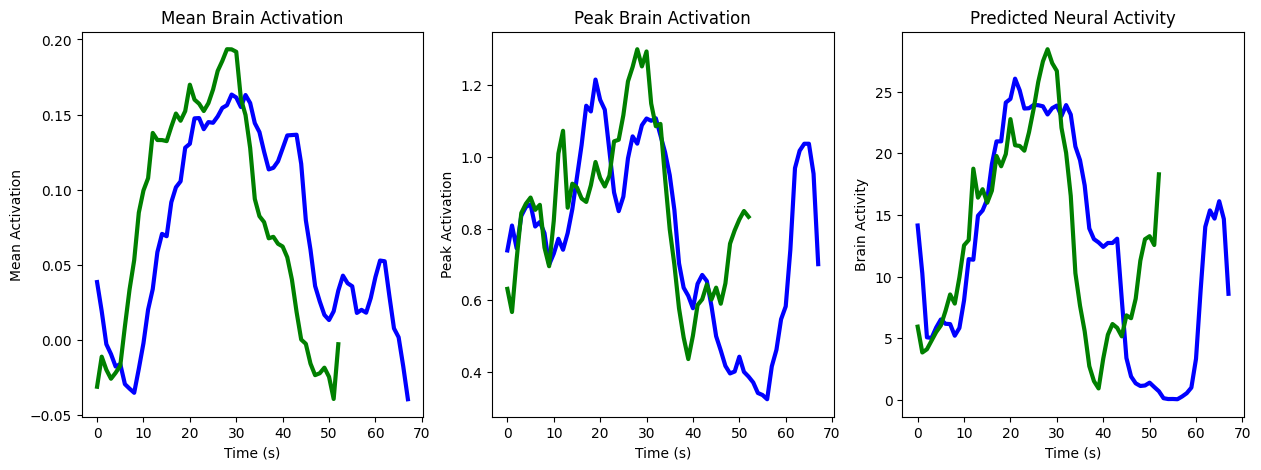

In [38]:
import matplotlib.pyplot as plt
import numpy as np

colors = {video_name: color for video_name, color in zip(results.keys(), list("bgrcmykw"))}
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

all_preds = np.concatenate(list(results.values()), axis=0)
threshold = np.mean(all_preds) + np.std(all_preds)

retention = {}

for video_name, preds in results.items():
    axes[0].plot(np.mean(preds, axis=1), label=video_name, linewidth=3, color=colors[video_name])
    axes[1].plot(np.max(preds, axis=1), label=video_name, linewidth=3, color=colors[video_name])
    
    engagement = np.mean(preds > threshold, axis=1)*100
    retention[video_name] = np.mean(engagement)
    axes[2].plot(engagement, label=video_name, linewidth=3, color=colors[video_name])
    
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Mean Activation")
axes[0].set_title("Mean Brain Activation")

axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Peak Activation")
axes[1].set_title("Peak Brain Activation")

axes[2].set_xlabel("Time (s)")
axes[2].set_ylabel("Brain Activity")
axes[2].set_title("Predicted Neural Activity")

In [39]:
actual_winner = "sintel_trailer-480p.mp4" # based on No. of views on youtube
print(f"FMRI responses correctly predicted better video: {actual_winner == max(retention, key=retention.get)}")

FMRI responses correctly predicted better video: True
